# Student Performance Prediction System

**Internship Mini Project (AI/ML)**

This notebook follows the complete ML workflow:

`Data → Cleaning → Analysis → Feature Selection → Training → Testing → Evaluation → Prediction`

> **Note:** This notebook uses a realistic *synthetic* dataset so it runs end-to-end with no downloads,
> which is handy in Google Colab. If you have a real dataset (e.g. the UCI "Student Performance" dataset
> or a Kaggle CSV), just replace the "Create / Load Dataset" cell with `pd.read_csv("your_file.csv")` —
> everything after that cell will keep working as long as the column names match, or you adjust them.


## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(style="whitegrid")
np.random.seed(42)


## 2. Create / Load Dataset

We simulate 500 students with features that realistically influence exam performance:
study hours, attendance, previous score, sleep hours, and two categorical features
(extracurricular activity and internet access).

**If you have a real CSV dataset**, replace this whole cell with:
```python
df = pd.read_csv("student_data.csv")
```


In [ ]:
n_students = 500

study_hours = np.round(np.random.normal(5, 2, n_students).clip(0, 12), 1)
attendance = np.round(np.random.normal(80, 12, n_students).clip(40, 100), 1)
previous_score = np.round(np.random.normal(65, 15, n_students).clip(20, 100), 1)
sleep_hours = np.round(np.random.normal(6.5, 1.2, n_students).clip(3, 10), 1)
extracurricular = np.random.choice(['Yes', 'No'], n_students, p=[0.4, 0.6])
internet_access = np.random.choice(['Yes', 'No'], n_students, p=[0.75, 0.25])

# Final score is built from a realistic combination of the features + random noise
noise = np.random.normal(0, 5, n_students)
final_score = (
    0.35 * study_hours * 5
    + 0.25 * attendance
    + 0.30 * previous_score
    + 0.10 * sleep_hours * 5
    + np.where(extracurricular == 'Yes', 2, 0)
    + np.where(internet_access == 'Yes', 3, 0)
    + noise
)
final_score = np.round(final_score.clip(0, 100), 1)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_score': previous_score,
    'sleep_hours': sleep_hours,
    'extracurricular': extracurricular,
    'internet_access': internet_access,
    'final_score': final_score
})

# Introduce a few realistic missing values and duplicates, so the cleaning step has real work to do
for col in ['attendance', 'sleep_hours']:
    idx = np.random.choice(df.index, size=10, replace=False)
    df.loc[idx, col] = np.nan

df = pd.concat([df, df.sample(5, random_state=1)], ignore_index=True)

df.head()


,study_hours,attendance,previous_score,sleep_hours,extracurricular,internet_access,final_score
0,6.0,91.1,86.0,7.4,No,Yes,68.6
1,4.7,100.0,78.9,5.8,Yes,Yes,55.9
2,6.3,NaN,65.9,5.5,Yes,Yes,52.5
3,8.0,86.8,55.3,6.5,Yes,Yes,62.0
4,4.5,72.2,75.5,NaN,No,Yes,55.6


## 3. Understand the Dataset

In [ ]:
print("Shape:", df.shape)
df.info()


Shape: (505, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   study_hours      505 non-null    float64
 1   attendance       495 non-null    float64
 2   previous_score   505 non-null    float64
 3   sleep_hours      495 non-null    float64
 4   extracurricular  505 non-null    object 
 5   internet_access  505 non-null    object 
 6   final_score      505 non-null    float64
dtypes: float64(5), object(2)
memory usage: 27.7+ KB


In [ ]:
df.describe()


,study_hours,attendance,previous_score,sleep_hours,final_score
count,505.000000,495.000000,505.000000,495.000000,505.000000
mean,5.024950,80.170303,66.574059,6.511515,54.997030
std,1.944092,11.183697,15.067987,1.166055,8.441231
min,0.000000,47.600000,21.600000,3.000000,30.000000
25%,3.600000,73.100000,56.000000,5.800000,49.200000
50%,5.000000,80.300000,66.800000,6.500000,55.200000
75%,6.300000,87.850000,76.300000,7.300000,60.400000
max,12.000000,100.000000,100.000000,10.000000,78.700000


## 4. Data Cleaning

In [ ]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
study_hours         0
attendance         10
previous_score      0
sleep_hours        10
extracurricular     0
internet_access     0
final_score         0
dtype: int64

Duplicate rows: 5


In [ ]:
# Handle missing values: fill numeric columns with median (robust to outliers)
for col in ['attendance', 'sleep_hours']:
    df[col] = df[col].fillna(df[col].median())

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicates after cleaning:", df.duplicated().sum())
print("Shape after cleaning:", df.shape)


Missing values after cleaning: 0
Duplicates after cleaning: 0
Shape after cleaning: (500, 7)


## 5. Exploratory Data Analysis (EDA)

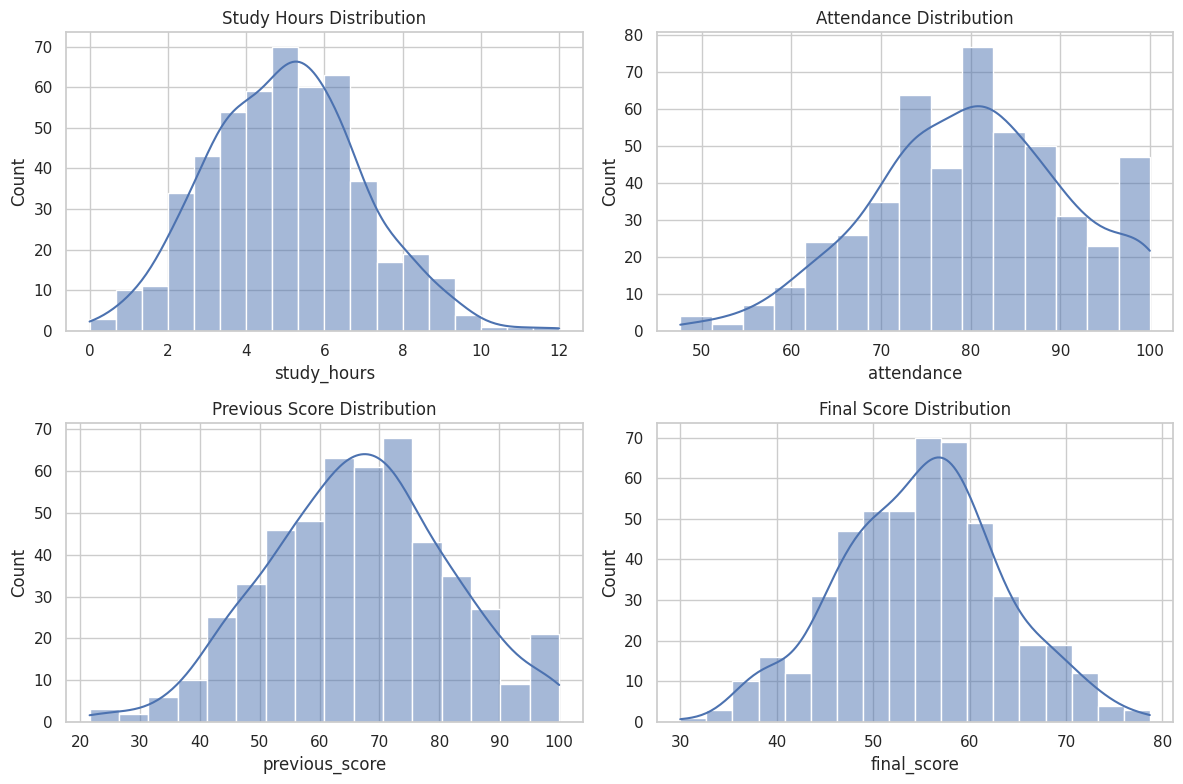

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['study_hours'], kde=True, ax=axes[0, 0]).set_title('Study Hours Distribution')
sns.histplot(df['attendance'], kde=True, ax=axes[0, 1]).set_title('Attendance Distribution')
sns.histplot(df['previous_score'], kde=True, ax=axes[1, 0]).set_title('Previous Score Distribution')
sns.histplot(df['final_score'], kde=True, ax=axes[1, 1]).set_title('Final Score Distribution')
plt.tight_layout()
plt.show()


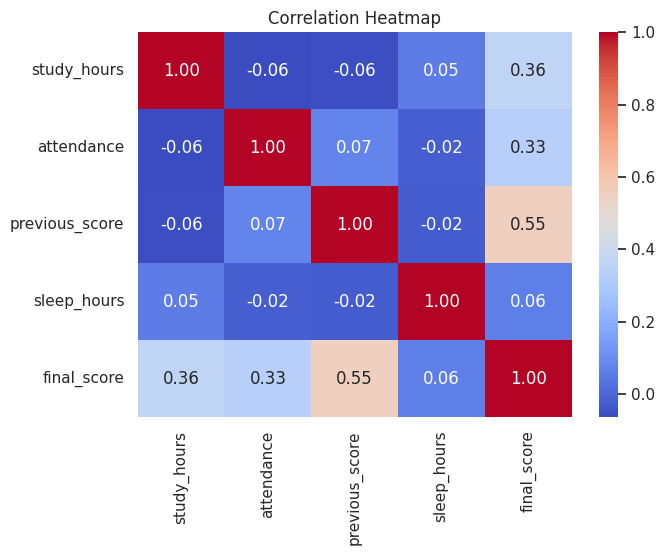

In [ ]:
numeric_cols = ['study_hours', 'attendance', 'previous_score', 'sleep_hours', 'final_score']
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


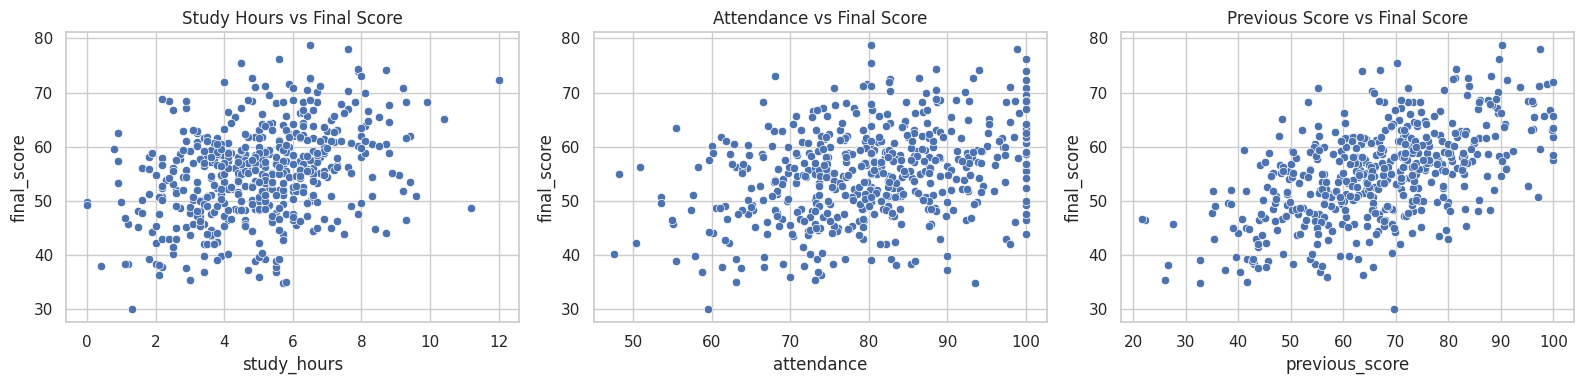

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x='study_hours', y='final_score', ax=axes[0]).set_title('Study Hours vs Final Score')
sns.scatterplot(data=df, x='attendance', y='final_score', ax=axes[1]).set_title('Attendance vs Final Score')
sns.scatterplot(data=df, x='previous_score', y='final_score', ax=axes[2]).set_title('Previous Score vs Final Score')
plt.tight_layout()
plt.show()


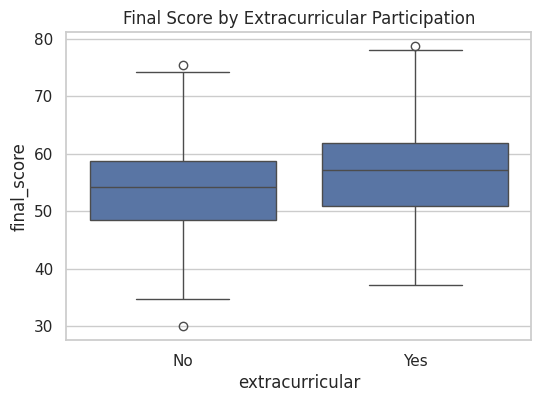

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='extracurricular', y='final_score')
plt.title('Final Score by Extracurricular Participation')
plt.show()


### EDA takeaways (example — rewrite these based on what YOU observe)
- `previous_score` and `study_hours` show the strongest positive correlation with `final_score`.
- `attendance` also correlates positively, but less strongly.
- Students doing extracurricular activities show a slightly higher median final score.

Write your own observations here before moving on — this is exactly what your mentor and report should reflect.


## 6. Feature Selection & Encoding

In [ ]:
# Encode categorical columns to numeric (Yes/No -> 1/0)
le = LabelEncoder()
df['extracurricular_enc'] = le.fit_transform(df['extracurricular'])   # Yes=1, No=0
df['internet_access_enc'] = le.fit_transform(df['internet_access'])

features = ['study_hours', 'attendance', 'previous_score', 'sleep_hours',
            'extracurricular_enc', 'internet_access_enc']
target = 'final_score'

X = df[features]
y = df[target]

X.head()


,study_hours,attendance,previous_score,sleep_hours,extracurricular_enc,internet_access_enc
0,6.0,91.1,86.0,7.4,0,1
1,4.7,100.0,78.9,5.8,1,1
2,6.3,80.3,65.9,5.5,1,1
3,8.0,86.8,55.3,6.5,1,1
4,4.5,72.2,75.5,6.5,0,1


## 7. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (400, 6)
Testing set: (100, 6)


## 8. Train Machine Learning Models

In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=5),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=200, max_depth=6)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained.")


Linear Regression trained.
Decision Tree trained.
Random Forest trained.


## 9. Evaluate Model Performance

In [ ]:
results = []
for name, model in trained_models.items():
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({'Model': name, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2 Score': round(r2, 3)})

results_df = pd.DataFrame(results).sort_values('R2 Score', ascending=False)
results_df


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.34,5.27,0.587
2,Random Forest,4.87,5.99,0.467
1,Decision Tree,5.58,7.04,0.264


In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f"Best performing model: {best_model_name}")


Best performing model: Linear Regression


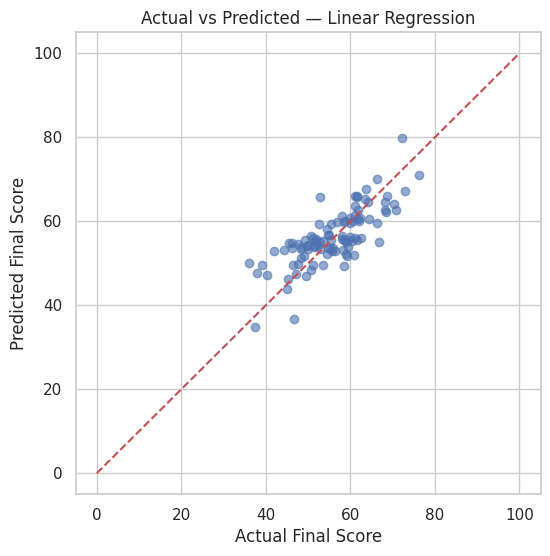

In [ ]:
# Visualize actual vs predicted for the best model
preds = best_model.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, preds, alpha=0.6)
plt.plot([0, 100], [0, 100], 'r--')
plt.xlabel('Actual Final Score')
plt.ylabel('Predicted Final Score')
plt.title(f'Actual vs Predicted — {best_model_name}')
plt.show()


## 10. Improve the Model (Cross-Validation)

In [ ]:
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='r2')
print(f"Cross-validation R2 scores: {np.round(cv_scores, 3)}")
print(f"Mean CV R2 score: {cv_scores.mean():.3f}")


Cross-validation R2 scores: [0.506 0.712 0.687 0.594 0.488]
Mean CV R2 score: 0.597


> Try improving further by:
> - Tuning hyperparameters (e.g. `n_estimators`, `max_depth`) with `GridSearchCV`
> - Adding/removing features and re-checking the R² score
> - Trying `Ridge`, `Lasso`, or `GradientBoostingRegressor` for comparison


## 11. Basic Prediction System

In [ ]:
def predict_student_performance(study_hours, attendance, previous_score,
                                 sleep_hours, extracurricular, internet_access):
    """
    Predicts a student's final score given their details.
    extracurricular / internet_access should be 'Yes' or 'No'.
    """
    input_df = pd.DataFrame([{
        'study_hours': study_hours,
        'attendance': attendance,
        'previous_score': previous_score,
        'sleep_hours': sleep_hours,
        'extracurricular_enc': 1 if extracurricular == 'Yes' else 0,
        'internet_access_enc': 1 if internet_access == 'Yes' else 0
    }])
    prediction = best_model.predict(input_df)[0]
    return round(prediction, 2)


# Example usage
sample_prediction = predict_student_performance(
    study_hours=6, attendance=85, previous_score=70,
    sleep_hours=7, extracurricular='Yes', internet_access='Yes'
)
print(f"Predicted Final Score: {sample_prediction}")


Predicted Final Score: 61.86


In [ ]:

print(predict_student_performance(2, 60, 40, 5, 'No', 'No'))
print(predict_student_performance(9, 95, 90, 8, 'Yes', 'Yes'))


31.37
76.66


## 12. Conclusion

- Built and compared three regression models (Linear Regression, Decision Tree, Random Forest) to predict student final scores.
- The **best model** was: *(fill in from your results table)*, with an R² score of *(fill in)*.
- Key drivers of performance were **previous_score**, **study_hours**, and **attendance**.
- Built a working prediction function that takes new student details and returns a predicted score.

### Possible next steps
- Replace the synthetic dataset with a real one (UCI / Kaggle) and re-run the whole notebook.
- Try classification instead (Pass/Fail) using `LogisticRegression` or `RandomForestClassifier`.
- Deploy the prediction function as a simple Streamlit app.

---
**Note to self:** rewrite the bullet points above with your own actual numbers and observations before submitting — this is your project report content.
